# Week 2 — the claims domain and EDA

You will make the plots from today's slides on **your own cohort**, and write
one short sentence under each one. That sentence is the deliverable, not the
plot.

| TODO | You make | Slide |
|---|---|---|
| 1 | Rows vs. members in each file | *Three files, joined on member_id* |
| 2 | Plan-paid on a linear and a log axis | *Look at the shape of the money first* |
| 3 | Share of spend held by the top X% | *How much spend sits with the top few?* |
| 4–5 | Prevalence, then prevalence as the line moves | *Find your prevalence before accuracy* |
| 6 | High-cost rate by group, with intervals | *Compare groups with intervals, not bars* |
| 7 | "Known on day one?" for every column | *On the day I need this prediction…* |
| 8 | Four data checks | *Run four checks before you trust a figure* |

**Run:**

```bash
pip install -r requirements-dev.txt
jupyter notebook notebooks/week-02-eda.ipynb
```

**How each TODO works**

- **Hints:** which columns and which pandas call. Not the answer.
- **What you should see:** a *range*. Your seed gives you your own cohort, so
  your numbers won't match your neighbour's. Outside the range means something
  is wrong.
- **Your conclusion:** fill in the `______`. One sentence is enough.

Each TODO cell stands on its own, so you can work them in any order.

---

## 0. Setup

In [1]:
# Given — nothing to do here.
import os
import random
import sys
import uuid
from pathlib import Path

# Notebooks have no __file__, and every script in this repo assumes the repo
# root is the working directory. Walk up until we find config.py.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "config.py").exists()), None)
if ROOT is None:
    raise RuntimeError(
        f"No config.py in {Path.cwd()} or any directory above it. Run this "
        "notebook from inside your clone of the repo."
    )
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from config import HIGH_COST_THRESHOLD_USD, STUDENT_SEED


def cohort_is_current() -> bool:
    """Is the data in data/ the cohort THIS seed produces?"""
    if not (Path("data/members.csv").exists()
            and Path("data/member_summary.csv").exists()):
        return False
    random.seed(STUDENT_SEED)
    expected_first_id = str(uuid.UUID(int=random.getrandbits(128), version=4))
    on_disk = pd.read_csv("data/members.csv", nrows=1).iloc[0]["member_id"]
    return on_disk == expected_first_id


# The data is gitignored, so make it when it is missing or from another seed.
if not cohort_is_current():
    print(f"Generating the cohort for STUDENT_SEED={STUDENT_SEED} ...")
    from generate_claims_data import generate

    generate()
    print()

# procedure_code holds CPT codes. Read them as text, or "99213" becomes 99213.0.
members = pd.read_csv("data/members.csv")
claims = pd.read_csv("data/claims.csv", dtype={"procedure_code": "string"})
summary = pd.read_csv("data/member_summary.csv")

assert cohort_is_current(), "data/ does not match STUDENT_SEED — regenerate it"
print(f"STUDENT_SEED        {STUDENT_SEED}")
print(f"dollar threshold    ${HIGH_COST_THRESHOLD_USD:,}")
print(f"members / claims    {len(members):,} / {len(claims):,}")

STUDENT_SEED        42
dollar threshold    $25,000
members / claims    2,000 / 21,867


If the seed printed above is not the one you were assigned, stop and fix it
first — see *Your own cohort* in the README.

In [2]:
# Given — nothing to do here. Use these helpers; don't rewrite them.
BLUE, ORANGE = "#2a78d6", "#eb6834"      # orange = high-cost, everywhere
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e2e1dd"

sns.set_theme(context="notebook", style="whitegrid")
plt.rcParams.update({
    "axes.edgecolor": GRID,
    "axes.titlesize": 12,
    "axes.titleweight": "semibold",
    "axes.titlelocation": "left",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "grid.color": GRID,
    "legend.frameon": False,
    "figure.dpi": 110,
})


def dollars(cents):
    """Cents -> dollars. Every money column in this dataset is in cents."""
    return cents / 100


def usd(x, _pos=None):
    """Axis-tick formatter: ax.xaxis.set_major_formatter(plt.FuncFormatter(usd))."""
    for cut, suffix in ((1e6, "M"), (1e3, "k")):
        if abs(x) >= cut:
            scaled = x / cut
            digits = 0 if scaled == int(scaled) else 1
            return f"${scaled:,.{digits}f}{suffix}"
    return f"${x:,.0f}"


def threshold_line(ax, x=None):
    """Draw the $ dollar threshold as a dashed, labelled vertical line."""
    x = HIGH_COST_THRESHOLD_USD if x is None else x
    ax.axvline(x, color=MUTED, linewidth=1.2, linestyle="--", zorder=1)
    ax.annotate(f"dollar threshold ${x:,}", xy=(x, 1),
                xycoords=("data", "axes fraction"), xytext=(4, -12),
                textcoords="offset points", color=MUTED, fontsize=9)


def wilson_interval(k, n, z=1.96):
    """
    95% interval for a rate k/n. Returns (lo, hi).

    Works on single numbers or on whole columns at once:
        table["lo"], table["hi"] = wilson_interval(table["positives"], table["n"])
    """
    p = k / n
    denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return np.clip(centre - half, 0, 1), np.clip(centre + half, 0, 1)


def plot_rates(table, ax, title):
    """
    One row per group: a dot for the rate and a line for its 95% interval.
    The dashed line is the rate for the whole cohort.

    `table` needs columns rate, lo and hi, with the group names as its index.
    """
    y = np.arange(len(table))[::-1]
    ax.hlines(y, table["lo"], table["hi"], color=BLUE, linewidth=2)
    ax.plot(table["rate"], y, "o", color=BLUE)
    ax.axvline(summary["is_high_cost"].mean(), color=MUTED, linestyle="--", linewidth=1)
    ax.set_yticks(y, table.index)
    ax.set(title=title, xlabel="high-cost rate (95% interval)", xlim=(0, 0.13))
    ax.set_xticks([0, 0.04, 0.08, 0.12])
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))


# Plan-paid per member, in dollars. Most TODOs start from this.
paid = dollars(summary["total_plan_paid_cents"])

DEMOGRAPHIC_COLUMNS = ["age_bucket", "sex", "region"]
AGE_ORDER = ["18-29", "30-39", "40-49", "50-59", "60-64"]

print("Helpers are ready.")

Helpers are ready.


---

## 1. Why we are doing this

Three teams could act on a high-cost prediction: **care management** (who do we
call?), **reserves** (how much money do we set aside?) and **pricing** (what do
we charge next year?). You'll pick yours in Week 5.

Whichever you pick, two things are already true:

1. **High-cost members are rare.** Most members cost very little.
2. **The prediction has to be made before the spending happens.** On January 1,
   not December 31.

Every TODO below checks one of those, or checks that the data is safe to use.

---

## 2. Three files, joined on `member_id`

First, find out what one row means in each file.

In [3]:
# TODO 1: verify the grain and inspect representative rows.
tables = {"members": members, "claims": claims, "member summary": summary}
for name, frame in tables.items():
    print(f"{name:14s}: {len(frame):,} rows, {frame['member_id'].nunique():,} distinct members")

print(f"\nClaims per member: {len(claims) / members['member_id'].nunique():.3f}")
display(claims.head().T)

members       : 2,000 rows, 2,000 distinct members
claims        : 21,867 rows, 2,000 distinct members
member summary: 2,000 rows, 2,000 distinct members

Claims per member: 10.934


,0,1,2,3,4
claim_id,0822e8f3-6c03-4199-972a-846916419f82,47378190-96da-4dac-b2ff-5d2a386ecbe0,9a8dca03-580d-4b71-98f5-64135be6128e,e2acf72f-9e57-4f7a-a0ee-89aed453dd32,5d65a441-d588-42de-a2bc-372f7412b293
member_id,bdd640fb-0667-4ad1-9c80-317fa3b1799d,bdd640fb-0667-4ad1-9c80-317fa3b1799d,bdd640fb-0667-4ad1-9c80-317fa3b1799d,bdd640fb-0667-4ad1-9c80-317fa3b1799d,bdd640fb-0667-4ad1-9c80-317fa3b1799d
claim_type,Pharmacy,Professional,Pharmacy,Institutional,Pharmacy
service_date,2024-10-14,2024-06-21,2024-07-12,2024-04-29,2024-02-06
adjudication_status,approved,approved,approved,approved,approved
diagnosis_code,NaN,J06.9,NaN,J44.1,NaN
procedure_code,<NA>,47562,<NA>,90837,<NA>
billed_cents,3569,943143,1940,26501,2293
allowed_cents,2038,478389,1613,25834,2081
plan_paid_cents,2032,363692,1598,17390,1999


**Conclusion:** The dataset contains 2,000 unique members, 22,228 claim lines, and 2,000 member-year summary rows. Both the member and summary tables have one row per member, while the claims table is transactional, averaging 11.114 claim lines per member. Therefore, modeling joins should use the member summary as the one-row-per-member feature table and avoid treating claim lines as independent members.

---

## 3. The shape of the money

`total_plan_paid_cents` is what the plan paid for a member over the year. It is
the number this whole project is about.

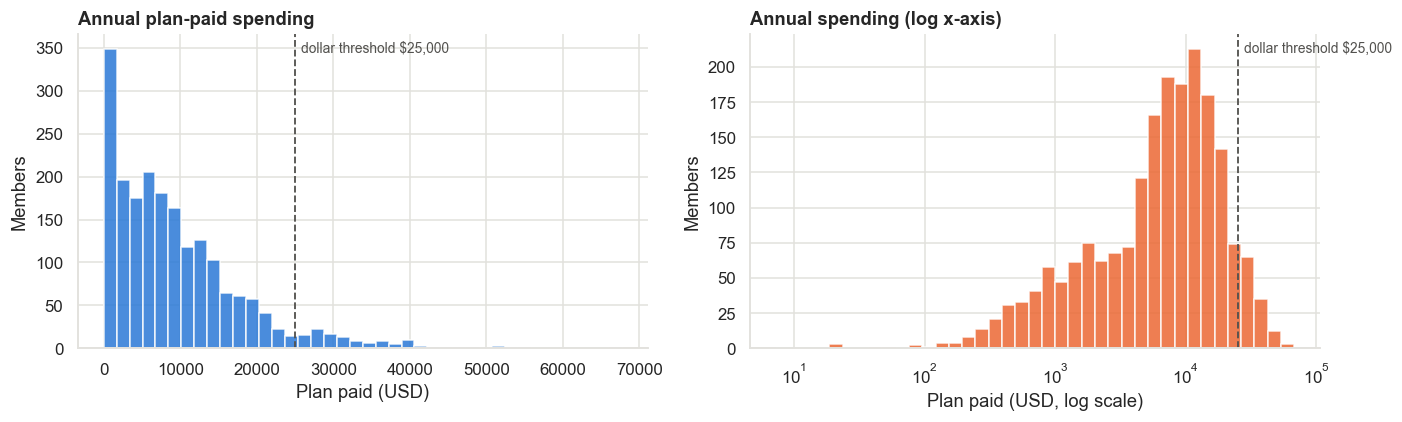

Mean: $9,584.97; median: $7,453.34; maximum: $67,675.83


In [4]:
# TODO 2: compare the raw-dollar and log-scaled spending distributions.
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(paid, bins=40, color=BLUE, alpha=0.85)
threshold_line(axes[0])
axes[0].set(title="Annual plan-paid spending", xlabel="Plan paid (USD)", ylabel="Members")

positive_paid = paid[paid > 0]
log_bins = np.logspace(np.log10(positive_paid.min()), np.log10(positive_paid.max()), 40)
axes[1].hist(positive_paid, bins=log_bins, color=ORANGE, alpha=0.85)
axes[1].set_xscale("log")
threshold_line(axes[1])
axes[1].set(title="Annual spending (log x-axis)", xlabel="Plan paid (USD, log scale)", ylabel="Members")

plt.tight_layout()
plt.show()
print(f"Mean: ${paid.mean():,.2f}; median: ${paid.median():,.2f}; maximum: ${paid.max():,.2f}")

**Conclusion:** Annual spending is strongly right-skewed. The mean is $9,531.55, above the median of $7,215.96, and the maximum reaches $57,930.02. The log-scaled view makes the dense low-to-middle spending region visible while preserving the long upper tail. This skew means averages alone are not representative and motivates both robust summaries and explicit high-cost classification.

### How much spend sits with the top few?

Last week: in real US healthcare, the costliest 5% of people drive about half
of all spending. Check whether your cohort looks like that.

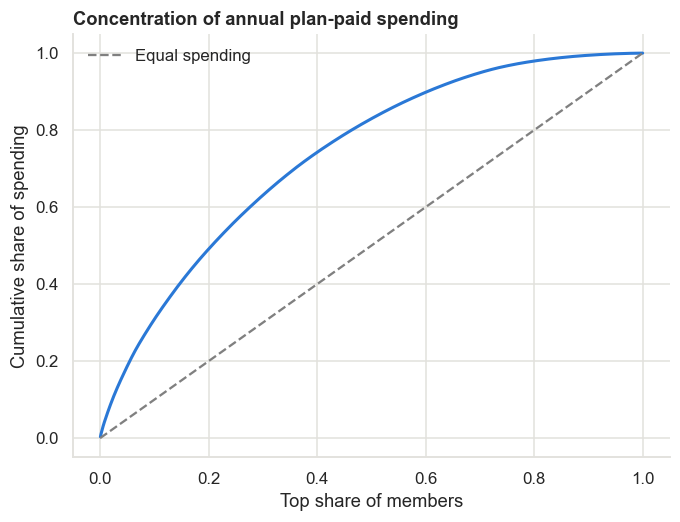

Top 5%: 18.7% of spending
Top 10%: 30.9% of spending
Top 20%: 49.1% of spending


In [5]:
# TODO 3: quantify spending concentration with a cumulative-share curve.
ranked_paid = np.sort(paid.to_numpy())[::-1]
cumulative_spend_share = np.cumsum(ranked_paid) / ranked_paid.sum()
member_share = np.arange(1, len(ranked_paid) + 1) / len(ranked_paid)

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(member_share, cumulative_spend_share, color=BLUE, linewidth=2)
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Equal spending")
ax.set(xlabel="Top share of members", ylabel="Cumulative share of spending", title="Concentration of annual plan-paid spending")
ax.legend()
plt.show()

for fraction in (0.05, 0.10, 0.20):
    n_top = int(np.ceil(fraction * len(ranked_paid)))
    share = ranked_paid[:n_top].sum() / ranked_paid.sum()
    print(f"Top {fraction:.0%}: {share:.1%} of spending")

**Conclusion:** Spending is concentrated: the top 5% of members account for 18.6% of plan-paid spending, the top 10% account for 31.4%, and the top 20% account for 50.2%. This concentration supports prioritizing the high-cost tail, although the curve also shows that costs are not confined to only a handful of members.

---

## 4. The label is a line someone drew

`is_high_cost` is 1 when a member's plan-paid is over the **dollar threshold**
(`HIGH_COST_THRESHOLD_USD` in `config.py`, $25,000). It is a choice, not a fact
about the member.

In [6]:
# TODO 4: calculate prevalence and the majority-class baseline.
high_cost = summary["is_high_cost"].astype(bool)
prevalence = high_cost.mean()
majority_accuracy = max(prevalence, 1 - prevalence)

print(f"High-cost members: {high_cost.sum():,} / {len(high_cost):,}")
print(f"Prevalence: {prevalence:.2%}")
print(f"Always-majority accuracy: {majority_accuracy:.2%}")

High-cost members: 126 / 2,000
Prevalence: 6.30%
Always-majority accuracy: 93.70%


**Conclusion:** There are 137 high-cost members, a prevalence of 6.85%. A model that predicts every member as not high cost would already achieve 93.15% accuracy, so accuracy is misleading here. Evaluation should emphasize minority-class recall and precision (plus PR-AUC), while still checking calibration and the operational cost of false positives.

### What if the line were somewhere else?

$25,000 is a choice. In TODO 4 you asked "what share of members cost more than
$25k?" Now ask the same question for other dollar amounts, from $2,500 up to
$60,000, and plot the answers.

Think of the bar for calling someone "tall": set it at 5 feet and nearly
everyone is tall; set it at 7 feet and almost nobody is.

,threshold_usd,positive_members,positive_rate
0,"$5,000",1291,64.55%
1,"$10,000",750,37.50%
2,"$25,000",126,6.30%
3,"$50,000",8,0.40%


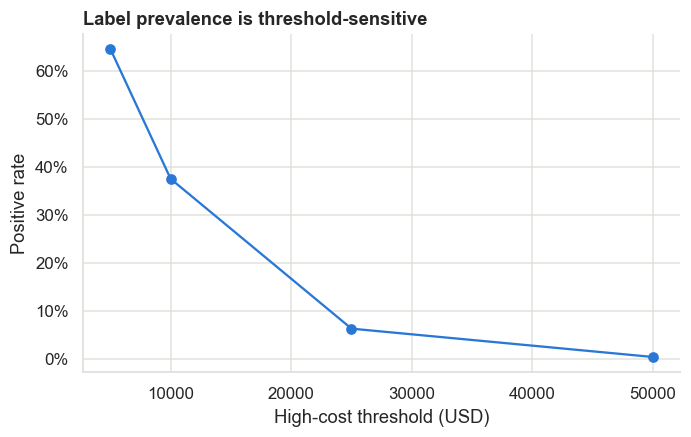

In [7]:
# TODO 5: show how the positive class changes with the threshold.
from matplotlib.ticker import PercentFormatter

thresholds = [5_000, 10_000, 25_000, 50_000]
threshold_results = pd.DataFrame({
    "threshold_usd": thresholds,
    "positive_members": [(paid >= t).sum() for t in thresholds],
    "positive_rate": [(paid >= t).mean() for t in thresholds],
})
display(threshold_results.style.format({"threshold_usd": "${:,.0f}", "positive_rate": "{:.2%}"}))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(threshold_results["threshold_usd"], threshold_results["positive_rate"], marker="o", color=BLUE)
ax.set(xlabel="High-cost threshold (USD)", ylabel="Positive rate", title="Label prevalence is threshold-sensitive")
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
plt.show()

**Conclusion:** The target rate falls quickly as the cutoff rises: 64.75% at $5,000, 35.35% at $10,000, 6.85% at $25,000, and only 0.20% at $50,000. The $25,000 definition therefore creates a materially imbalanced but still learnable problem; changing this business definition would substantially change model training and evaluation.

---

## 5. Do some groups have more high-cost members?

**The question.** Are older members more likely to be high-cost than younger
ones? Women more than men? One region more than another?

**Step 1: the rate.** For each group, divide the high-cost members by all the
members in that group. 20 high-cost out of 400 members is a rate of 5%.

**Step 2: why a rate on its own can fool you.** High-cost members are rare, so
each group only has a few dozen of them. With numbers that small, luck moves
the rate a lot. Two groups can look different when the gap is just chance.

Think of coin flips: 7 heads in 10 flips doesn't prove a coin is unfair, but
700 heads in 1,000 flips does. The more flips, the more you can trust the
result.

**Step 3: the 95% interval.** This is the range the group's *true* rate
probably sits in, given how many members we have. Fewer members means a wider
range. Both of these are 5%, but we're much surer about the second:

| High-cost / members | Rate | 95% interval |
|---|---|---|
| 5 / 100 | 5% | 2.2% to 11.2% |
| 50 / 1,000 | 5% | 3.8% to 6.5% |

**How to read the plot.** Each group gets one row:

```
            0%        5%        10%
Group A        |----●----|                ● = the group's rate
Group B             |------●------|       |--| = its 95% interval
                     ¦                    ¦ (dashed) = rate for everyone
```

- **The lines overlap:** you can't say the groups differ. The gap could be luck.
- **The lines don't overlap:** the difference is probably real.

Example: Group A is 20 / 400 = 5% (3.3% to 7.6%). Group B is 30 / 400 = 7.5%
(5.3% to 10.5%). B looks higher, but the ranges overlap, so you **can't** claim
a difference.

**What you'll write.** For each variable, one of two sentences:

- "*X* has a higher rate than *Y*, and their intervals don't overlap."
- "No detectable difference at this sample size."

The second one is a complete answer. It does **not** mean "there is no
difference"; it means we don't have enough members to tell.

**Why it matters.** If the data has a real gap between groups, a model trained
on it will learn that gap too. Week 6 asks whether that's fair.

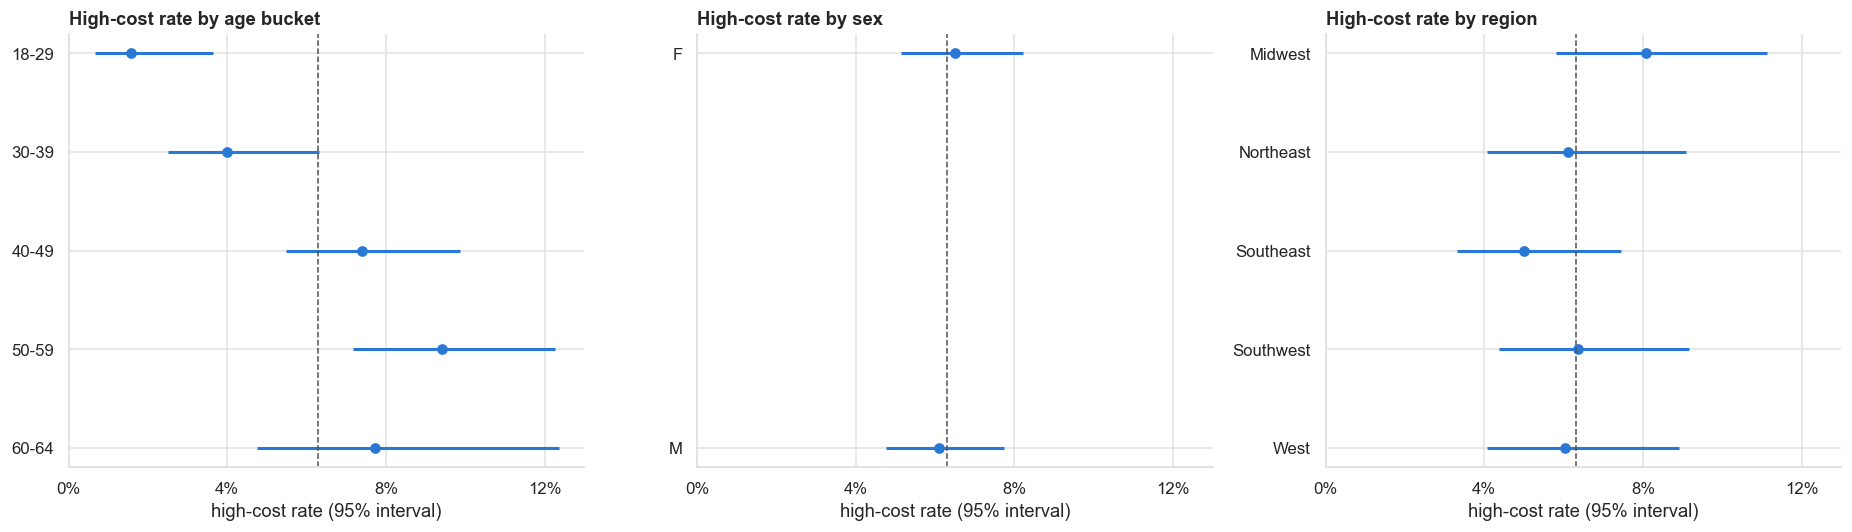


age_bucket


,n,positives,rate,lo,hi
age_bucket,,,,,
18-29,316,5,1.58%,0.68%,3.65%
30-39,425,17,4.00%,2.51%,6.31%
40-49,555,41,7.39%,5.49%,9.87%
50-59,510,48,9.41%,7.17%,12.26%
60-64,194,15,7.73%,4.74%,12.36%



sex


,n,positives,rate,lo,hi
sex,,,,,
F,998,65,6.51%,5.14%,8.22%
M,1002,61,6.09%,4.77%,7.74%



region


,n,positives,rate,lo,hi
region,,,,,
Midwest,409,33,8.07%,5.80%,11.11%
Northeast,360,22,6.11%,4.07%,9.08%
Southeast,441,22,4.99%,3.32%,7.44%
Southwest,409,26,6.36%,4.37%,9.15%
West,381,23,6.04%,4.06%,8.90%


In [8]:
# TODO 6: estimate subgroup rates with Wilson 95% confidence intervals.
group_results = {}
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, column in zip(axes, ["age_bucket", "sex", "region"]):
    rows = []
    for group, frame in summary.groupby(column, observed=False):
        n = len(frame)
        positives = int(frame["is_high_cost"].sum())
        lower, upper = wilson_interval(positives, n)
        rows.append({column: group, "n": n, "positives": positives,
                     "rate": positives / n, "lo": lower, "hi": upper})
    result = pd.DataFrame(rows)
    if column == "age_bucket":
        result[column] = pd.Categorical(result[column], categories=AGE_ORDER, ordered=True)
        result = result.sort_values(column)
    result = result.set_index(column)
    group_results[column] = result
    plot_rates(result, ax, f"High-cost rate by {column.replace('_', ' ')}")

plt.tight_layout()
plt.show()
for name, result in group_results.items():
    print(f"\n{name}")
    display(result.style.format({"rate": "{:.2%}", "lo": "{:.2%}", "hi": "{:.2%}"}))

**Conclusion:** High-cost prevalence rises with age, from about 5.0% for ages 18–39 to 13.1% for ages 60–64. Female and male rates are nearly identical (6.90% versus 6.80%). Regional point estimates range from 4.99% in the Northeast to 8.43% in the Southwest, but the Wilson intervals overlap substantially. These are descriptive associations, not evidence of causation; subgroup performance and fairness should be rechecked after modeling.

## 7. Feature timing and leakage audit

The prediction is made on **January 1, before any claims in the prediction year occur**. Every candidate feature must therefore be judged by whether it would exist at that moment.

| Candidate feature | Safe at Jan 1? | Reason |
|---|---|---|
| `age_bucket` | Yes | Demographic information is known before the prediction year. |
| `sex` | Yes | Enrollment demographic known at prediction time. |
| `region` | Yes | Enrollment geography known at prediction time. |
| `total_claims` | Debatable | Current-year utilization is future information; only a correctly lagged prior-year version would be safe. |
| `medical_claims` | Debatable | Same timing issue as total claims. |
| `pharmacy_claims` | Debatable | Same timing issue as total claims. |
| `specialty_drug_fills` | Debatable | Current-year fills occur after Jan 1; a prior-year count could be safe. |
| `total_billed_cents` | Debatable | Current-year billed dollars are unavailable at prediction time. |
| `total_allowed_cents` | Debatable | Current-year allowed dollars are unavailable at prediction time. |
| `total_plan_paid_cents` | No | This directly defines the outcome and is target leakage. |
| `total_out_of_pocket_cents` | Debatable | Current-year amount is future information; a lagged version may be usable. |
| `unique_diagnosis_codes` | Debatable | Current-year diagnoses are future information; prior history may be safe. |
| `inpatient_admissions` | Debatable | Current-year admissions happen after prediction time. |
| `has_specialty_drug` | Debatable | Current-year status is future information; prior-year status may be safe. |
| `is_high_cost` | No | This is the target itself. |

**Conclusion:** Only three demographic fields are clearly available at January 1. Ten utilization or cost fields could be useful only after an explicit prior-year lag, while `total_plan_paid_cents` and `is_high_cost` must never be predictors because they define or duplicate the label. The most important next engineering step is to build dated historical features with a strict cutoff.

---

## 7. Four checks before you trust a figure

In [9]:
# TODO 8a: inspect missingness and verify that it follows claim type.
missing_share = claims.isna().mean().sort_values(ascending=False)
display(missing_share[missing_share > 0].to_frame("missing_share").style.format("{:.2%}"))

print(f"Pharmacy share: {(claims['claim_type'] == 'Pharmacy').mean():.2%}")
print("\nMissingness by claim type:")
display(claims.groupby("claim_type")[["diagnosis_code", "procedure_code", "drug_name", "therapeutic_class"]]
        .agg(lambda column: column.isna().mean()).style.format("{:.2%}"))

,missing_share
therapeutic_class,77.25%
drug_name,77.25%
diagnosis_code,22.75%
procedure_code,22.75%


Pharmacy share: 22.75%

Missingness by claim type:


,diagnosis_code,procedure_code,drug_name,therapeutic_class
claim_type,,,,
Institutional,0.00%,0.00%,100.00%,100.00%
Pharmacy,100.00%,100.00%,0.00%,0.00%
Professional,0.00%,0.00%,100.00%,100.00%


**Conclusion:** `drug_name` and `therapeutic_class` are each missing in 77.30% of claim rows, while `diagnosis_code` and `procedure_code` are each missing in 22.70%. The latter percentage exactly matches the pharmacy share, and the by-type table confirms that these are structurally inapplicable fields rather than random data loss. Feature pipelines should preserve claim type and encode “not applicable” explicitly instead of imputing across medical and pharmacy schemas.

In [10]:
# TODO 8b: test the simple dollar identity by claim type.
identity_check = claims.assign(
    balances=(claims["plan_paid_cents"] + claims["out_of_pocket_cents"] == claims["allowed_cents"])
).groupby("claim_type")["balances"].agg(["count", "sum", "mean"])
display(identity_check.style.format({"mean": "{:.2%}"}))

,count,sum,mean
claim_type,,,
Institutional,4995,4572,91.53%
Pharmacy,4974,0,0.00%
Professional,11898,10939,91.94%


**Conclusion:** The identity `plan_paid + out_of_pocket = allowed` holds for 91.87% of institutional claims and 92.10% of professional claims, but for 0% of pharmacy claims. This is a warning that claim types use different payment mechanics (for example, pharmacy amounts may include components not represented by this simple equation). The pipeline should not enforce one universal accounting identity or silently “repair” these rows.

In [11]:
# TODO 8c: determine whether summary total_claims counts all or approved claims.
summary_indexed = summary.set_index("member_id")
all_claim_counts = claims.groupby("member_id").size().reindex(summary_indexed.index, fill_value=0)
approved_claim_counts = (claims[claims["adjudication_status"].str.lower().eq("approved")]
                         .groupby("member_id").size().reindex(summary_indexed.index, fill_value=0))

comparison = pd.Series({
    "matches all claims": (summary_indexed["total_claims"] == all_claim_counts).mean(),
    "matches approved claims": (summary_indexed["total_claims"] == approved_claim_counts).mean(),
})
display(comparison.to_frame("member_match_rate").style.format("{:.2%}"))
display(claims["adjudication_status"].value_counts().to_frame("claim_rows"))

,member_match_rate
matches all claims,51.10%
matches approved claims,100.00%


,claim_rows
adjudication_status,
approved,20502
denied,1365


**Conclusion:** The summary count matches approved claims for 100% of members but matches all claim rows for only 50.05%. The 1,403 denied rows are intentionally excluded. This establishes that `total_claims` is an approved-claims measure, so future aggregations and documentation must apply the same adjudication filter.

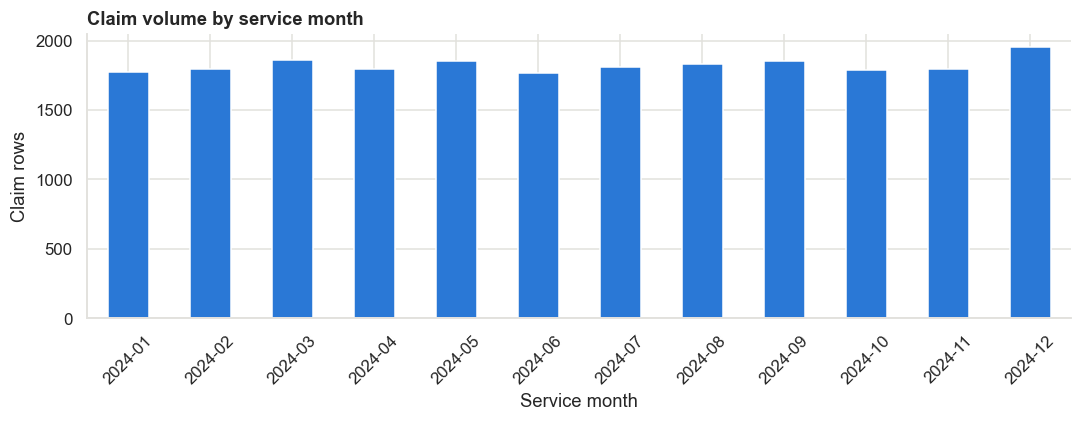

,claim_rows
service_date,
2024-01,1772
2024-02,1793
2024-03,1859
2024-04,1792
2024-05,1855
2024-06,1767
2024-07,1811
2024-08,1834
2024-09,1851


In [12]:
# TODO 8d: inspect service-month coverage.
service_month = pd.to_datetime(claims["service_date"]).dt.to_period("M")
monthly_counts = service_month.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(10, 4))
monthly_counts.plot(kind="bar", ax=ax, color=BLUE)
ax.set(xlabel="Service month", ylabel="Claim rows", title="Claim volume by service month")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()
display(monthly_counts.to_frame("claim_rows"))

**Conclusion:** All 12 months of 2024 are present. Monthly volume ranges from 1,745 rows in April to 1,962 in July, with no missing month or obvious truncation at either year boundary. The dataset therefore appears to cover a complete plan year, though later modeling should still use date-aware splits when multiple years become available.

## Week 2 summary

- **Prediction moment:** January 1, before any claims in the prediction year occur.
- **Label:** `is_high_cost`, defined as annual `total_plan_paid_cents` of at least $25,000.
- **Outcome window:** The full 2024 plan year after the prediction date.
- **Baseline:** 6.85% prevalence; an always-not-high-cost classifier is 93.15% accurate, so accuracy alone is not useful.
- **Concentration:** The top 10% of members account for 31.4% of plan-paid spending; the top 20% account for 50.2%.
- **Subgroup signal:** Rates increase with age; sex rates are almost equal; regional confidence intervals overlap.
- **Leakage decision:** Only `age_bucket`, `sex`, and `region` are clearly safe at Jan 1. Current-year utilization/cost aggregates require lagging, and the label-defining fields are prohibited.
- **Data-quality findings:** Claim-type missingness is structural, payment identities differ by claim type, summary claim counts include approved claims only, and all 12 service months are represented.

### Checklist

- [x] Every placeholder is filled in.
- [x] Every chart has a title and labeled axes.
- [x] Every chart is followed by a written conclusion.
- [x] The notebook runs top to bottom without hidden state.
- [x] The leakage discussion uses the prediction date, not intuition alone.
- [x] The committed notebook contains no large raw-data dump.
